# Making the model without time in the input


In [4]:
# number of epochs with no improvement after which training will be stopped
EARLY_STOPPING = 100
RETUNE_BY_OVERWRITING = False


# the folder with the training/validation/test datasets
DATASET_FOLDER = "../../data/datasets"
TUNER_RESULTS_FOLDER = "../../data/tuner_results"


## Setting up parallelism

In [5]:
import os

NUMBER_OF_PHYSICAL_CODES = 10

def setup_threading(n_physical_cores):
    if not isinstance(n_physical_cores, int) or n_physical_cores < 1:
        raise ValueError("Number of physical cores must be a positive integer")
    omp_n_cores = n_physical_cores
    intra_cores = n_physical_cores
    inter_cores = max(1, n_physical_cores // 4)

    os.environ["OMP_NUM_THREADS"] = str(omp_n_cores)
    os.environ["TF_NUM_INTRAOP_THREADS"] = str(intra_cores)
    os.environ["TF_NUM_INTEROP_THREADS"] = str(inter_cores)

    os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # Hide INFO and WARNING messages


## Load the necessary modules and data

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, r2_score
import tensorflow as tf
from keras_tuner import Hyperband
from neuralns import mnn


data = mnn.read_datasets(DATASET_FOLDER)

I0000 00:00:1789211289.656018   42742 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1789211289.656949   42742 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1789211289.715892   42742 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1789211291.036918   42742 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

  0%|          | 0/5 [00:00<?, ?it/s]

In [7]:
TUNING_PARAMS = {
    "n_hidden": [2, 4, 8],
    "n_neurons": [16, 32, 64, 128],
    "learning_rate": [0.01, 0.001, 0.0001],
    "dropout": [0.0],           # it was found ineffective
    "l1": [0.0, 1.0e-6, 1.0e-7, 1.0e-8],
    "l2": [0.0],                # it was found ineffective
    "activation": ["relu"],     # `sigmoid`` was found ineffective
    "reduce_lr_patience": [0],  # it was found ineffective
}

tr = mnn.InputOutputTransformer(
    x_features=['logL', 'logP', 'logPdot'],
    y_reg_vars= ['logB', 'M', 'logB0', 'logt'],
    y_cls_var='env=H', data=data['train'])

def build_model(hp):
    def choice(parameter_name):
        return hp.Choice(parameter_name, TUNING_PARAMS[parameter_name])

    return mnn.MultioutNN(
        transformer=tr,
        n_hidden=choice("n_hidden"),
        n_neurons=choice("n_neurons"),
        learning_rate=choice("learning_rate"),
        dropout=choice("dropout"),
        reduce_lr_patience=choice("reduce_lr_patience"),
        l1=choice("l1"),
        l2=choice("l2"),
        activation=choice("activation"),
        early_stopping=EARLY_STOPPING,
        verbose=False).model

tuner = Hyperband(build_model, objective="val_loss",
                  max_epochs=30,
                  directory=TUNER_RESULTS_FOLDER,
                  project_name="wout",
                  hyperband_iterations=1,
                  overwrite=RETUNE_BY_OVERWRITING,
                 )

E0000 00:00:1789211291.490324   42742 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


## Start the hyperparameter optimization

In [8]:
tuner.search(
    x=tr.transform("X", data["train"]),
    y=[tr.transform("Y_reg", data["train"]), tr.transform("Y_cls", data["train"])],
    batch_size=64,
    validation_data=[tr.transform("X", data["valid"]), [tr.transform("Y_reg", data["valid"]), tr.transform("Y_cls", data["valid"])]],
    verbose=True,
    epochs=100,
)

Trial 90 Complete [00h 00m 22s]
val_loss: 0.42261138558387756

Best val_loss So Far: 0.31167203187942505
Total elapsed time: 00h 10m 47s


## Visualize the performance of the optimal model

Classification accuracy of `env=H`: 0.8342
R^2 score of prediction of `logB`: 0.9994
R^2 score of prediction of `M`: 0.5272
R^2 score of prediction of `logB0`: 0.9931
R^2 score of prediction of `logt`: 0.9982


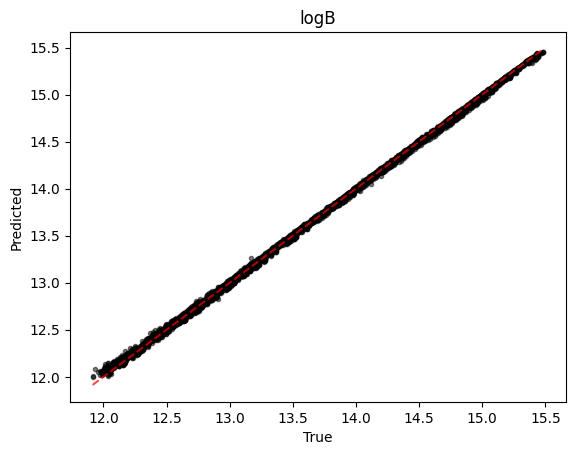

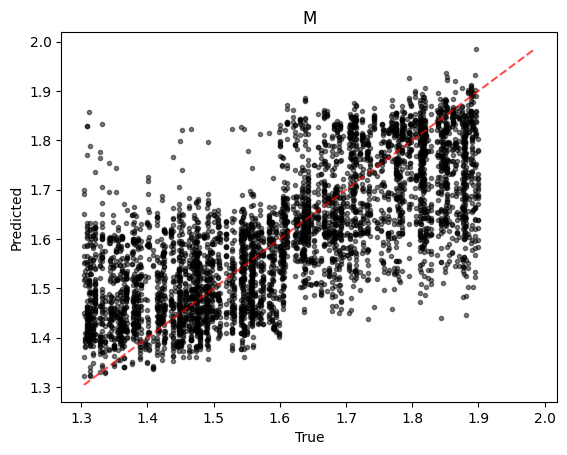

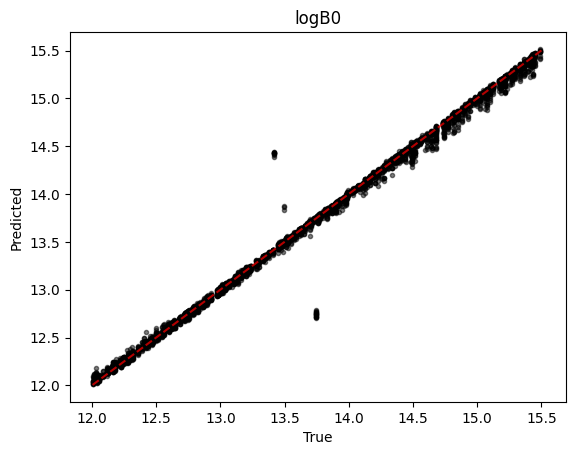

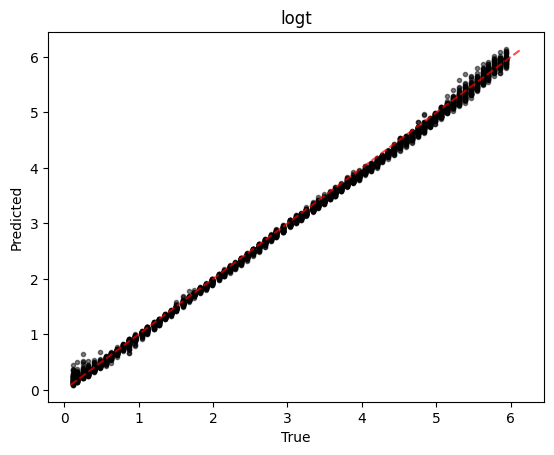

In [9]:
best_model = tuner.get_best_models(num_models=1)[0]
best_mnn = mnn.MultioutNN(transformer=tr, verbose=False)
best_mnn.model = best_model
# best_model.
Y_reg_pred, Y_cls_pred = best_mnn.predict(data["test"])

y_cls_var = best_mnn.transformer.y_cls_var
acc = accuracy_score(data["test"][y_cls_var], Y_cls_pred)
print(f"Classification accuracy of `{y_cls_var}`: {acc:.4g}")

for i, var in enumerate(best_mnn.transformer.y_reg_vars):
    y_reg_pred = Y_reg_pred[var]
    y_reg_true = data["test"][var]
    r2 = r2_score(y_reg_true, y_reg_pred)
    print(f"R^2 score of prediction of `{var}`: {r2:.4g}")

    y_min = min(min(y_reg_true), min(y_reg_pred))
    y_max = max(max(y_reg_true), max(y_reg_pred))

    yy = np.linspace(y_min, y_max, 31)

    plt.figure()
    plt.plot(y_reg_true, y_reg_pred, "k.", alpha=0.5)
    plt.plot(yy, yy, "r--", alpha=0.7)
    plt.title(var)
    plt.xlabel("True")
    plt.ylabel("Predicted")
plt.show()

## Export tuner results in CSV format

In [10]:

results = []

for trial_id, trial in tuner.oracle.trials.items():
    entry = trial.hyperparameters.values.copy()   # hyperparameters dict
    entry['score'] = trial.score                  # objective score
    results.append(entry)

results = pd.DataFrame(results)
results = results.sort_values("score", ascending=True)
results.to_csv(os.path.join(tuner.project_dir, "results.csv"), index_label="trial_id")
results

,n_hidden,n_neurons,learning_rate,dropout,reduce_lr_patience,l1,l2,activation,tuner/epochs,tuner/initial_epoch,tuner/bracket,tuner/round,score,tuner/trial_id
84,8,128,0.0010,0.0,0,1.000000e-07,0.0,relu,30,10,1,1,0.311672,0077
72,4,128,0.0100,0.0,0,1.000000e-08,0.0,relu,30,10,2,2,0.358849,0067
82,4,128,0.0010,0.0,0,1.000000e-06,0.0,relu,30,10,1,1,0.361151,0075
73,4,64,0.0100,0.0,0,1.000000e-06,0.0,relu,30,10,2,2,0.361425,0069
83,8,64,0.0010,0.0,0,0.000000e+00,0.0,relu,30,10,1,1,0.368497,0076
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4,8,32,0.0001,0.0,0,1.000000e-06,0.0,relu,2,0,3,0,1.085171,NaN
28,4,32,0.0001,0.0,0,1.000000e-07,0.0,relu,2,0,3,0,1.197871,NaN
64,4,16,0.0001,0.0,0,1.000000e-07,0.0,relu,4,0,2,0,1.204364,NaN
20,8,16,0.0001,0.0,0,0.000000e+00,0.0,relu,2,0,3,0,1.767556,NaN


## Get weights of best model, and report optimal hyperparameters

In [11]:
best_hyper = tuner.get_best_hyperparameters()[0]
best_hyper = best_hyper.values
best_hyper = {key: value for key, value in best_hyper.items() if not key.startswith("tuner/")}
best_model = tuner.get_best_models()[0]
best_weights = best_model.weights
del best_model
best_hyper

/home/konstantinos/miniconda3/envs/neuralns/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 42 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


{'n_hidden': 8,
 'n_neurons': 128,
 'learning_rate': 0.001,
 'dropout': 0.0,
 'reduce_lr_patience': 0,
 'l1': 1e-07,
 'l2': 0.0,
 'activation': 'relu'}

## Refit the best model to obtain the final model

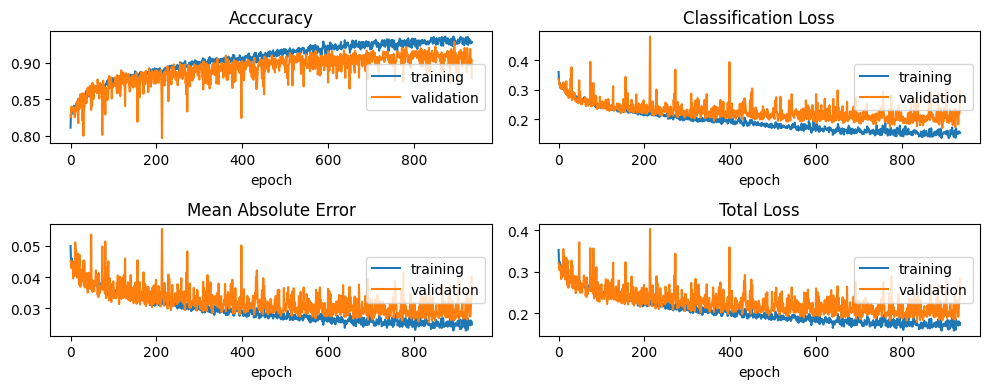

Acccuracy
	training         	 (min:    0.811, max:    0.936, cur:    0.929)
	validation       	 (min:    0.797, max:    0.929, cur:    0.879)
Classification Loss
	training         	 (min:    0.135, max:    0.360, cur:    0.153)
	validation       	 (min:    0.170, max:    0.481, cur:    0.296)
Mean Absolute Error
	training         	 (min:    0.023, max:    0.050, cur:    0.025)
	validation       	 (min:    0.025, max:    0.055, cur:    0.040)
Total Loss
	training         	 (min:    0.158, max:    0.352, cur:    0.171)
	validation       	 (min:    0.179, max:    0.403, cur:    0.284)
228/228 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - clsout_accuracy: 0.9289 - clsout_loss: 0.1525 - loss: 0.1715 - regout_loss: 0.0248 - regout_mean_absolute_error: 0.0248 - val_clsout_accuracy: 0.8792 - val_clsout_loss: 0.2956 - val_loss: 0.2840 - val_regout_loss: 0.0401 - val_regout_mean_absolute_error: 0.0401


In [12]:
best_mnn = mnn.MultioutNN(transformer=tr, early_stopping=EARLY_STOPPING, **best_hyper)
best_mnn.model.set_weights(best_weights)
best_mnn.fit(training_data=data["train"], validation_data=data["valid"], epochs=10000)
best_mnn.save(os.path.join(tuner.project_dir, "refit_best_model.mod"))